In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Load the movies data with 'latin1' encoding
movies = pd.read_csv('movies.dat', sep='::', names=['MovieID', 'Title', 'Genres'], engine='python', encoding='latin1')

# Load the ratings data with 'latin1' encoding
ratings = pd.read_csv('ratings.dat', sep='::', names=['UserID', 'MovieID', 'Rating', 'Timestamp'], engine='python', encoding='latin1')

# Load the users data with 'latin1' encoding
users = pd.read_csv('users.dat', sep='::', names=['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code'], engine='python', encoding='latin1')

# Merge the ratings and users DataFrames
merged = pd.merge(pd.merge(ratings, users), movies)



In [15]:
# Split the genres column and create a new entry for each genre
merged = merged.assign(Genres = merged['Genres'].str.split('|')).explode('Genres')

# get the unique genres
genres = merged['Genres'].unique()


# Initialize the algorithm
counts = {genre: 0 for genre in genres}
averages = {genre: 0 for genre in genres}

# Define the horizon and the number of experiments
n = 50000
num_experiments = 100


# Calculate the frequency of each rating for each genre
rating_freq = merged.groupby('Genres')['Rating'].value_counts(normalize=True)

# Pre-calculate the ratings and probabilities arrays for each genre
rating_dist = {genre: (rating_freq[genre].index, rating_freq[genre].values)
               for genre in rating_freq.index.levels[0]}

def pull_arm(chosen_genre):
    # Check if there are any movies of this genre left
    if chosen_genre not in rating_dist:
        return 0

    # Sample a rating from the pre-calculated distribution
    ratings, probabilities = rating_dist[chosen_genre]
    reward = ratings[np.random.multinomial(1, probabilities).argmax()]

    return reward





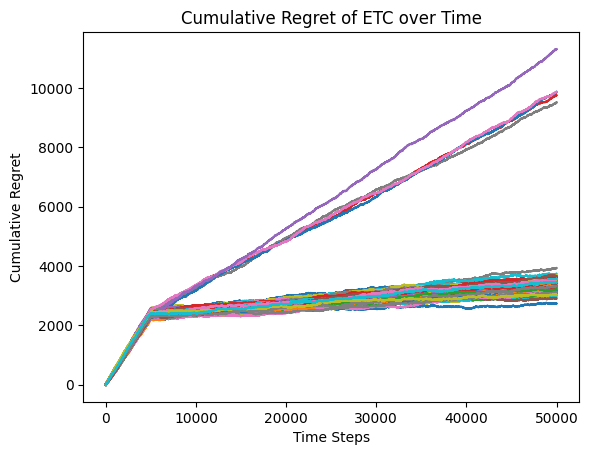

In [16]:
np.random.seed(122)

# get the number of arms
k = len(genres)

# Set the length of the exploration phase
m = n // (10 * k) # Use integer division to ensure m is an integer

cumulative_regret = np.zeros((num_experiments, n))


# Exploration phase
for t in range(m * k):
    chosen_arm = genres[t % k]  # Cycle through the arms
    reward = pull_arm(chosen_arm)
    counts[chosen_arm] += 1
    averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]

# Calculate the optimal reward
optimal_reward = max(averages.values())

# Run the ETC algorithm
for experiment in range(num_experiments):
    # Reset the counts, averages, and cumulative regret at the start of each experiment
    counts = {genre: 0 for genre in genres}
    averages = {genre: 0 for genre in genres}

    # Exploration phase
    for t in range(m * k):
        chosen_arm = genres[t % k]  # Cycle through the arms
        reward = pull_arm(chosen_arm)
        counts[chosen_arm] += 1
        averages[chosen_arm] = ((averages[chosen_arm] * (counts[chosen_arm] - 1)) + reward) / counts[chosen_arm]

        # Calculate the regret
        regret = optimal_reward - reward

        # Store the cumulative regret
        cumulative_regret[experiment, t] = (cumulative_regret[experiment, t-1] if t > 0 else 0) + regret

    # Exploitation phase
    best_arm = max(averages, key=averages.get)
    for t in range(m * k, n):
        reward = pull_arm(best_arm)
        counts[best_arm] += 1
        averages[best_arm] = ((averages[best_arm] * (counts[best_arm] - 1)) + reward) / counts[best_arm]

        # Calculate the regret
        regret = optimal_reward - reward

        # Store the cumulative regret
        cumulative_regret[experiment, t] = cumulative_regret[experiment, t-1] + regret


# Plot the cumulative regret
# Plot the cumulative regret
for experiment in range(num_experiments):
    plt.plot(cumulative_regret[experiment])
plt.xlabel('Time Steps')  # X-axis label
plt.ylabel('Cumulative Regret')  # Y-axis label
plt.title('Cumulative Regret of ETC over Time')  # Title of the plot
plt.show()

